In [1]:
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mticker # used for percentage ticks

In [2]:
from analysis import *

There are 3 real clones that have < 2 observation times.


## Figure

In [3]:
supplemental_mode = True

scenarios = ['r36_rp0_mimic', 'r36_rp2_mimic', 'full_pipeline']
scenarios_labels = ['Model\n$rp=0$', 'Model\n$rp=2$', 'Exp. data']

if supplemental_mode:
    scenarios.extend(['full_pipeline_trunc', 'no_collapse'])
    scenarios_labels.extend(['Exp. data\n(trunc.)', 'Exp. data\n(no cluster)'])

mapping = dict(zip(scenarios, scenarios_labels))

df2 = df.query('scenario.isin(@scenarios)').copy()
df2['scenario'] = df2['scenario'].map(mapping)

overall_pass = df2.groupby('scenario', as_index = False).agg({'pass_null': 'mean'})
overall_pass['percent_pass'] = overall_pass['pass_null'] * 100
overall_pass['scenario'] = pd.Categorical(
    overall_pass['scenario'],
    categories=scenarios_labels,
    ordered=True
)

overall_pass = overall_pass.sort_values('scenario').reset_index(drop=True)
overall_pass

,scenario,pass_null,percent_pass
0,Model\n$rp=0$,0.022115,2.211538
1,Model\n$rp=2$,0.872748,87.274840
2,Exp. data,0.873646,87.364621
3,Exp. data\n(trunc.),0.860000,86.000000
4,Exp. data\n(no cluster),0.876506,87.650602


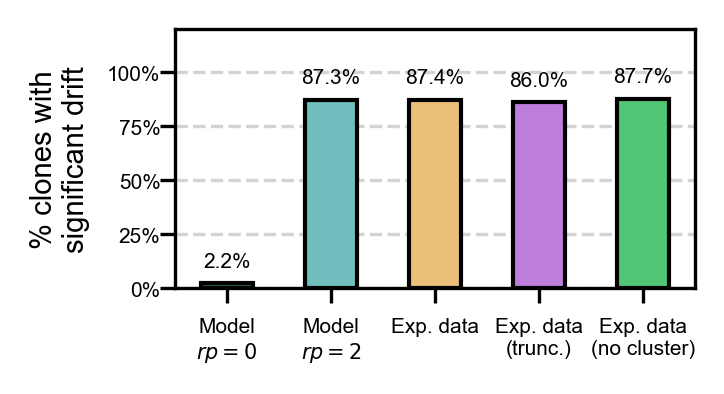

In [5]:
# plt.style.use('default')
plt.rcParams.update(small_label_settings)

if supplemental_mode:
    fig, ax = plt.subplots(figsize = (2.3, 1.2), dpi = 300, constrained_layout = True)
    filepath = os.path.join('images', 'null_hypothesis_supplement.svg')
else:
    fig, ax = plt.subplots(figsize = (1.8, 1.2), dpi = 300)
    filepath = os.path.join('images', 'null_hypothesis.svg')

palette = {
    'Model\n$rp=0$': hue(0),
    'Model\n$rp=2$': hue(2),
    'Exp. data': exp_hue,
    'Exp. data\n(no cluster)': no_collapse_hue,
    'Exp. data\n(trunc.)': trunc_hue
}

order = scenarios_labels

ax = sns.barplot(
    data=overall_pass, x='scenario', y='percent_pass',
    edgecolor='black', hue='scenario', palette=palette, legend=False,
    width = 0.5, order = scenarios_labels, zorder = 2
)

ax.grid(True, linestyle='--', linewidth=0.8, color='lightgray', axis = 'y', zorder=-1)

plt.ylabel("% clones with\nsignificant drift")
plt.xlabel('')
plt.xticks(rotation=0, ha='center')

for i, row in overall_pass.iterrows():
    percent_pass = row['percent_pass']
    ax.annotate(
        f'{percent_pass:.1f}%',
        (i, percent_pass),
        ha = 'center', va = 'bottom',
        fontsize = 5, color = 'black', xytext = (0, 3),
        textcoords = 'offset points'
    )

ax.set_ylim(0, 120)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=100))
ax.tick_params(axis='y', pad = 0)
ax.set_yticks([0, 25, 50, 75, 100])

plt.savefig(filepath, pad_inches = 0)